# Marker and peak-to-gene heatmaps

`epione.pl.marker_heatmap` and `epione.pl.peak2gene_heatmap` are line-by-line ports of
ArchR's `plotMarkerHeatmap` (`markerHeatmap`) and `plotPeak2GeneHeatmap`
(`peak2GeneHeatmap`). Everything ArchR computes before drawing — the `cutOff`
filter, log2 / row-z-score scaling, binary row sorting, `hclust` column order,
ComplexHeatmap's dendrogram reordering, `kmeans` link groups and the `nPlot`
subsampling — is reproduced, including R's random-number streams, so
`return_matrix=True` gives the same numbers as ArchR's `returnMatrix = TRUE`.

| ArchR | Epione |
|---|---|
| `getMarkerFeatures()` | `epi.tl.find_marker_features()` |
| `plotMarkerHeatmap(seMarker, cutOff, ...)` | `epi.pl.marker_heatmap(markers, cut_off, ...)` |
| `plotMarkerHeatmap(..., returnMatrix = TRUE)` | `epi.pl.marker_heatmap(..., return_matrix=True)` / `epi.pl.marker_heatmap_matrix()` |
| `addPeak2GeneLinks()` | `epi.tl.peak_to_gene()` |
| `plotPeak2GeneHeatmap(proj, k, nPlot, ...)` | `epi.pl.peak2gene_heatmap(**epi.pl.prepare_peak2gene_heatmap(...))` |
| `plotPeak2GeneHeatmap(..., returnMatrices = TRUE)` | `epi.pl.peak2gene_heatmap(..., return_matrices=True)` |

We use the ArchR hematopoiesis tutorial data (BMMC, CD34+ BMMC and PBMC; 10,660
cells, 11 clusters, hg19) so the last section can compare against ArchR run on
the very same project.

In [1]:
import os, sys, json, shutil, subprocess, pathlib, time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import matplotlib.pyplot as plt
from IPython.display import display, Image

import epione as epi

# Tables exported from the ArchR hematopoiesis project (see make_fixture.R) and
# the ArchR reference run for the parity section (tests/parity/marker_heatmap/ref_archr.R).
FIX = pathlib.Path('/scratch/users/steorra/analysis/25_epione/epione_dev/fixture/tables')
WORK = pathlib.Path('/scratch/users/steorra/analysis/25_epione/epione_dev/work/marker-heatmap')
CACHE = WORK / 'cache'; CACHE.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.dpi'] = 80

## Load the data

Gene scores and the peak matrix come straight from the ArchR project
(`getMatrixFromProject`), together with cluster labels, UMAP and the iterative-LSI
embedding. The first run converts the Matrix-Market files into cached `.h5ad`.

In [2]:
def read_mtx(path):
    with open(path) as f:
        line = f.readline()
        while line.startswith('%'):
            line = f.readline()
        nr, nc, nnz = map(int, line.split())
    d = pd.read_csv(path, sep=' ', comment='%', header=None, skiprows=1,
                    dtype={0: np.int32, 1: np.int32, 2: np.float32})
    d = d.iloc[1:] if len(d) == nnz + 1 else d
    return sp.csr_matrix((d[2].to_numpy(), (d[1].to_numpy() - 1, d[0].to_numpy() - 1)), shape=(nc, nr))

def load(name):
    h5 = CACHE / f'{name}.h5ad'
    if h5.exists():
        return ad.read_h5ad(h5)
    cells = pd.read_csv(FIX / 'cells.tsv', sep='\t', index_col=0)
    lsi = pd.read_csv(FIX / 'lsi.tsv', sep='\t', index_col=0)
    if name == 'genescore':
        bc = open(FIX / 'GeneScoreMatrix_cells.txt').read().split()
        X = read_mtx(FIX / 'GeneScoreMatrix.mtx')
        var = pd.read_csv(FIX / 'GeneScoreMatrix_features.tsv', sep='\t').set_index('name')
    else:
        bc = open(FIX / 'PeakMatrix_cells.txt').read().split()
        X = read_mtx(FIX / 'PeakMatrix.mtx')
        pk = pd.read_csv(FIX / 'peaks.tsv', sep='\t')
        var = pd.DataFrame({'chrom': pk.seqnames.values, 'start': pk.start.values, 'end': pk.end.values},
                           index=pk.peak.values)
    a = ad.AnnData(X, obs=cells.loc[bc].copy(), var=var)
    a.var_names = a.var_names.astype(str)
    a.obsm['X_iterative_lsi'] = lsi.loc[bc].to_numpy()
    a.obsm['X_umap'] = a.obs[['UMAP1', 'UMAP2']].to_numpy()
    a.obs['log10_nFrags'] = np.log10(a.obs['nFrags'])
    a.write_h5ad(h5)
    return a

gs = load('genescore')
pk = load('peaks')
gs, pk

(AnnData object with n_obs × n_vars = 10660 × 23127
     obs: 'Sample', 'TSSEnrichment', 'ReadsInTSS', 'ReadsInPromoter', 'ReadsInBlacklist', 'PromoterRatio', 'PassQC', 'NucleosomeRatio', 'nMultiFrags', 'nMonoFrags', 'nFrags', 'nDiFrags', 'BlacklistRatio', 'Clusters', 'ReadsInPeaks', 'FRIP', 'UMAP1', 'UMAP2', 'log10_nFrags'
     var: 'seqnames', 'start', 'end', 'strand', 'idx'
     obsm: 'X_iterative_lsi', 'X_umap',
 AnnData object with n_obs × n_vars = 10660 × 141369
     obs: 'Sample', 'TSSEnrichment', 'ReadsInTSS', 'ReadsInPromoter', 'ReadsInBlacklist', 'PromoterRatio', 'PassQC', 'NucleosomeRatio', 'nMultiFrags', 'nMonoFrags', 'nFrags', 'nDiFrags', 'BlacklistRatio', 'Clusters', 'ReadsInPeaks', 'FRIP', 'UMAP1', 'UMAP2', 'log10_nFrags'
     var: 'chrom', 'start', 'end'
     obsm: 'X_iterative_lsi', 'X_umap')

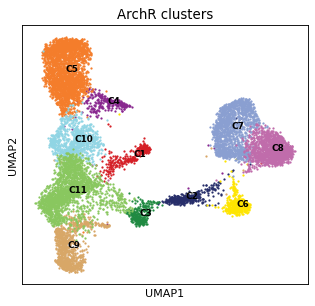

In [3]:
from epione.pl._marker_heatmap import palette_discrete
pal = palette_discrete(gs.obs['Clusters'])
fig, ax = plt.subplots(figsize=(4.6, 4.2))
for c, col in pal.items():
    m = (gs.obs['Clusters'] == c).to_numpy()
    ax.scatter(*gs.obsm['X_umap'][m].T, s=1, c=col, label=c, rasterized=True)
    ax.text(*np.median(gs.obsm['X_umap'][m], axis=0), c, fontsize=8, weight='bold')
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2')
ax.set_title('ArchR clusters'); plt.show()

## Part 1 · Marker feature heatmap

`epi.tl.find_marker_features` tests each cluster against a bias-matched
background (TSS enrichment and log10 fragments, as in ArchR's
`getMarkerFeatures(bias = ...)`). `epi.pl.marker_heatmap` then takes the
long-form table directly; ArchR's assay names are available in `cut_off`
(`Mean`, `MeanBGD`, `Log2FC`, `FDR`, `Pval`), written with R syntax and R's NA
semantics.

In [4]:
%%time
markers_gs = epi.tl.find_marker_features(
    gs, group_by='Clusters', bias_vars=['TSSEnrichment', 'log10_nFrags'], seed=1, verbose=False)
markers_gs.sort_values('log2_fc', ascending=False).head()

CPU times: user 27.4 s, sys: 6.4 s, total: 33.8 s
Wall time: 33.8 s


,group,feature,mean_fg,mean_bg,pct_fg,pct_bg,log2_fc,U,z,p_value,fdr,n_fg,n_bg
121235,C6,MYL2,0.313540,0.0,0.063205,0.0,18.258293,101265.0,5.294981,1.190284e-07,0.000006,443,430
53380,C3,SNORD115-32,0.245651,0.0,0.003322,0.0,17.906258,43790.0,0.981557,3.263179e-01,0.611451,301,290
59356,C3,MIR3606,0.220937,0.0,0.016611,0.0,17.753281,44370.0,2.202282,2.764539e-02,0.158224,301,290
50651,C3,MIR34B,0.214887,0.0,0.019934,0.0,17.713226,44515.0,2.414527,1.575564e-02,0.112811,301,290
60605,C3,MIR4760,0.212990,0.0,0.023256,0.0,17.700434,44660.0,2.610203,9.048850e-03,0.080832,301,290


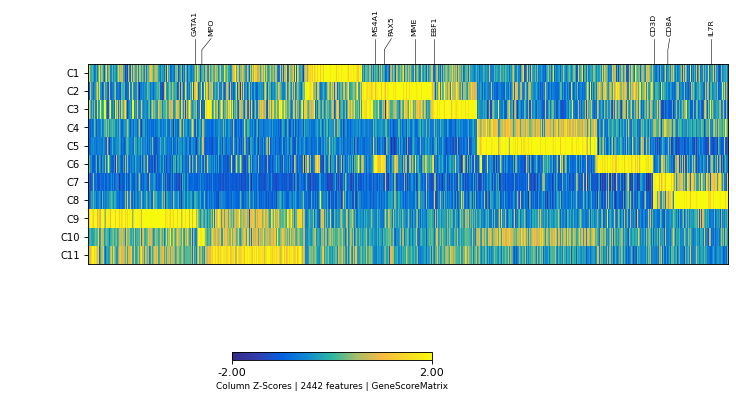

In [5]:
marker_genes = ['CD34', 'GATA1', 'PAX5', 'MS4A1', 'EBF1', 'MME', 'CD14', 'CEBPB', 'MPO',
                'IRF8', 'CD3D', 'CD8A', 'TBX21', 'IL7R']
fig, res = epi.pl.marker_heatmap(
    markers_gs, cut_off='FDR <= 0.01 & Log2FC >= 1.25',
    label_markers=marker_genes, transpose=True, use_matrix='GeneScoreMatrix',
    figsize=(10, 5), show=False)
plt.show()

`return_matrix=True` returns exactly the matrix ArchR draws (rows = features in
binary-sorted order, columns = clusters; the transposed version when
`transpose=True`). `marker_heatmap_matrix` also exposes the display order,
the `cut_off` pass matrix and the labels.

In [6]:
mat = epi.pl.marker_heatmap(markers_gs, cut_off='FDR <= 0.01 & Log2FC >= 1.25',
                            use_matrix='GeneScoreMatrix', return_matrix=True)
print(mat.shape)
res = epi.pl.marker_heatmap_matrix(markers_gs, cut_off='FDR <= 0.01 & Log2FC >= 1.25',
                                   use_matrix='GeneScoreMatrix')
print('cluster order (hclust):', list(mat.columns[res.col_order]))
mat.round(2).head()

(2442, 11)


cluster order (hclust): ['C9', 'C10', 'C11', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8']


,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11
LINC01343,-0.39,-0.58,1.22,-0.50,-0.88,-0.74,-1.12,-0.52,1.67,0.46,1.39
TAL1,-0.06,-0.32,-0.31,-0.57,-0.06,-0.95,-0.92,-0.93,2.00,0.56,1.49
CADM3-AS1,-0.17,-0.76,-0.45,-0.35,-0.30,-0.67,-0.83,-0.79,1.84,0.60,1.87
ACKR1,-0.13,-0.76,-0.38,-0.33,-0.24,-0.68,-0.96,-0.86,1.79,0.79,1.78
FGFR2,-0.02,-0.73,0.65,-0.92,-0.81,-0.64,-1.06,-0.19,2.00,0.46,1.16


Peak markers work the same way. ArchR uses the `solarExtra` palette for
non-gene-score matrices.

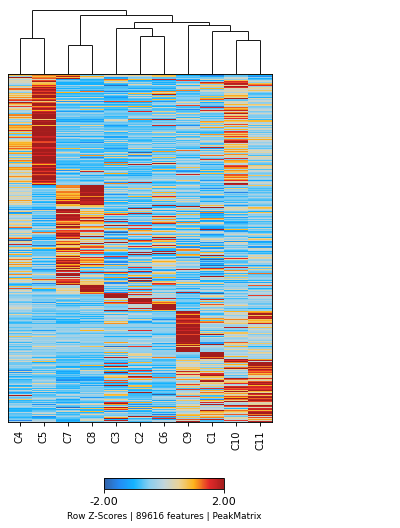

89616 marker peaks
CPU times: user 2min 19s, sys: 35 s, total: 2min 54s
Wall time: 2min 54s


In [7]:
%%time
markers_pk = epi.tl.find_marker_features(
    pk, group_by='Clusters', bias_vars=['TSSEnrichment', 'log10_nFrags'], seed=1, verbose=False)
fig, res_pk = epi.pl.marker_heatmap(markers_pk, cut_off='FDR <= 0.1 & Log2FC >= 0.5',
                                    use_matrix='PeakMatrix', n_label=0, figsize=(6, 7), show=False)
plt.show()
print(res_pk.matrix.shape[0], 'marker peaks')

## Part 2 · Peak-to-gene heatmap

`epi.tl.peak_to_gene` links peaks to genes (gene scores here, as in the ArchR
run) over 500 kNN metacells. `epi.pl.prepare_peak2gene_heatmap` rebuilds
ArchR's inputs from that run: the same metacells, log2-normalised to 10⁴, and
the `VarQATAC` / `VarQRNA` variance quantiles. The heatmap keeps links with
r ≥ 0.45, FDR ≤ 1e-4 and both variance quantiles above 0.25. It groups them
into `k = 25` kmeans clusters and shows at most `nPlot = 25,000`.

In [8]:
%%time
genes = pd.read_csv(FIX / 'genes_hg19.tsv', sep='\t')
gene_ann = pd.DataFrame({'gene_name': genes.symbol, 'chrom': genes.seqnames,
                         'start': genes.start, 'end': genes.end, 'strand': genes.strand})
links = epi.tl.peak_to_gene(pk, rna=gs, gene_annotation=gene_ann, use_rep='X_iterative_lsi',
                            n_metacells=500, k_neighbors=100, max_distance=250_000,
                            seed=1, verbose=False)
prep = epi.pl.prepare_peak2gene_heatmap(pk, gs, links=links)
print(f'{len(links):,} peak-gene pairs tested')

1,100,582 peak-gene pairs tested
CPU times: user 13.4 s, sys: 3.39 s, total: 16.8 s
Wall time: 16.2 s


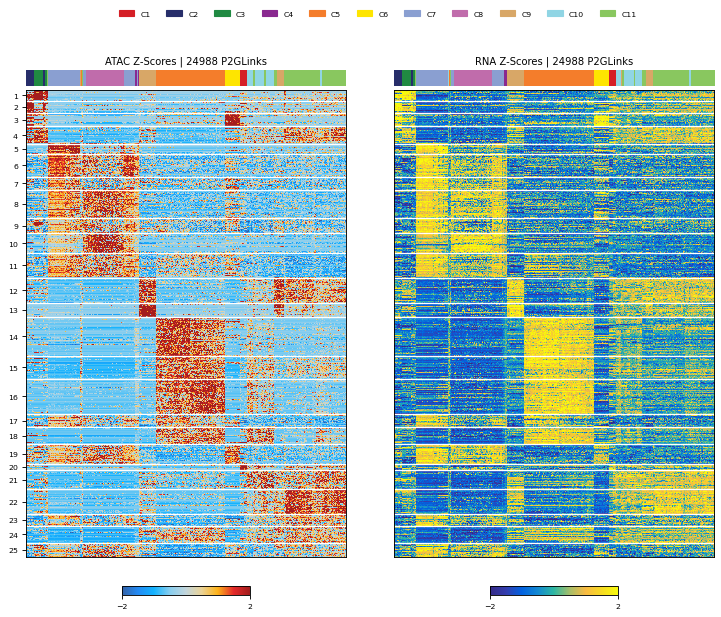

24988 links shown in 25 kmeans groups
CPU times: user 9.52 s, sys: 2.21 s, total: 11.7 s
Wall time: 11.7 s


In [9]:
%%time
fig, p2g = epi.pl.peak2gene_heatmap(**prep, cell_groups=pk.obs['Clusters'].to_numpy(),
                                    k=25, n_plot=25_000, seed=1, figsize=(10, 8), show=False)
plt.show()
print(p2g.atac.shape[0], 'links shown in', len(np.unique(p2g.kmeans_id)), 'kmeans groups')

In [10]:
# Genes behind each kmeans block (top 5 by number of links)
blk = p2g.links.assign(kmeans=p2g.kmeans_id)
blk.groupby('kmeans')['gene'].agg(lambda g: ', '.join(g.value_counts().index[:5])).head(10)

kmeans
1         NRXN2, MYBPH, CBFA2T3, VPREB1, BMS1P20
2       VPREB1, BMS1P20, RSPH14, MIR549A, MIR650
3            TCOF1, ZCCHC7, SP110, CD74, MIR4432
4          DIPK1B, CES5AP1, CUEDC1, HRAT92, LSM7
5               FYN, MRPL10, RUNX3, ADGRE5, CD8B
6          SLC35G6, RNF167, CIRBP, DUSP2, ADRA2B
7             S1PR5, CISD3, POLR2A, HAGHL, MORN3
8     BCL11B, RASGRP1, HIST1H3G, LINC-PINT, SIX5
9           CIRBP, POLR2A, PHF1, MIR4754, RNF167
10                  LEF1, TCF7, RHOH, ICOS, IL7R
Name: gene, dtype: object

## Part 3 · Parity vs ArchR

`tests/parity/marker_heatmap/ref_archr.R` runs ArchR 1.0.3 on the same project:

* `getMarkerFeatures` (gene scores and peaks) followed by `plotMarkerHeatmap` in 9
  configurations. These cover transpose, invert, `plotLog2FC`,
  `binaryClusterRows = FALSE`, `subsetMarkers`, `clusterCols = FALSE`,
  `scaleRows = FALSE`, `log2Norm = FALSE` and `abs()` / `!` cut-offs. We save
  `returnMatrix = TRUE`, the drawn row/column order (`row_order(draw(ht))`) and
  the anno_mark labels.
* `addPeak2GeneLinks` followed by `plotPeak2GeneHeatmap(returnMatrices = TRUE)` for
  `k = 25, nPlot = 25000, seed = 1` (66k links, so the subsampling path runs) and
  `k = 12, nPlot = 4000, seed = 7`. R's `kmeans` labels are also saved.

To isolate the heatmap step, ArchR's marker statistics and links go into Epione
unchanged. Gates were registered in `tests/parity/marker_heatmap/MANIFEST.md`
before any comparison. A deterministic output passes when the max abs error is at most 1e-8 and
names and orders are identical. The free-running kmeans passes at ARI ≥ 0.95.

Note on RNG: `addArchRThreads(threads > 1)` switches R to
`RNGkind("L'Ecuyer-CMRG")`. `peak2gene_heatmap` therefore defaults to
`rng_kind="L'Ecuyer-CMRG"`, and also implements R's Mersenne-Twister. Hartigan-Wong
`kmeans`, `hclust`, `dist`, `rowMeans` (long double) and `matrixStats::rowSds`
are ported from R's C/Fortran code, so even the free-running `kmeans` matches.

In [11]:
import importlib.util
pc_path = pathlib.Path(epi.__file__).parents[1] / 'tests' / 'parity' / 'marker_heatmap' / 'parity_check.py'
spec = importlib.util.spec_from_file_location('parity_check', pc_path)
pc = importlib.util.module_from_spec(spec); spec.loader.exec_module(pc)
REF = WORK / 'ref'

mk = pc.marker_parity(REF)
tab = pd.DataFrame(mk).T[['n_features', 'max_abs_err', 'rows_equal', 'cols_equal', 'nan_pattern_equal',
                          'row_order_equal', 'col_order_equal', 'labels_equal', 'label_positions_equal']]
tab

,n_features,max_abs_err,rows_equal,cols_equal,nan_pattern_equal,row_order_equal,col_order_equal,labels_equal,label_positions_equal
gs_default,2519,0.0,True,True,True,True,True,True,True
gs_rows,2519,0.0,True,True,True,True,True,True,True
gs_log2fc,8659,0.0,True,True,True,True,True,True,True
gs_nobinary,1567,0.0,True,True,True,True,True,True,True
gs_subset,12,0.0,True,True,True,True,True,True,True
pk_default,35425,0.0,True,True,True,True,True,True,True
pk_rows,35425,0.0,True,True,True,True,True,True,True
pk_invert,31373,0.0,True,True,True,True,True,True,True
pk_nocluster,21347,0.0,True,True,True,True,True,True,True


In [12]:
pg = pc.p2g_parity(REF)
rows = []
for tag, rec in pg.items():
    for mode in ('injected', 'free'):
        r = rec[mode]
        rows.append({'config': tag, 'kmeans': 'R labels injected' if mode == 'injected' else 'Python (free-running)',
                     'n_links': r['n_links'], 'ATAC max|Δ|': r['atac_max_abs_err'], 'RNA max|Δ|': r['rna_max_abs_err'],
                     'kmeans ARI': r.get('kmeans_ari', np.nan),
                     'kmeansId / cols / groups / links / kDF identical': all(r[k] for k in (
                         'kmeans_id_equal', 'col_order_equal', 'col_groups_equal', 'links_equal', 'kdf_equal'))})
pd.DataFrame(rows)

,config,kmeans,n_links,ATAC max|Δ|,RNA max|Δ|,kmeans ARI,kmeansId / cols / groups / links / kDF identical
0,p2g_default,R labels injected,24988,0.0,0.0,NaN,True
1,p2g_default,Python (free-running),24988,0.0,0.0,1.0,True
2,p2g_small,R labels injected,3994,0.0,0.0,NaN,True
3,p2g_small,Python (free-running),3994,0.0,0.0,1.0,True


Next, the ArchR heatmap (rendered from ArchR's own PDF) beside Epione's,
both drawn from ArchR's `getMarkerFeatures` output (`gs_rows` configuration).

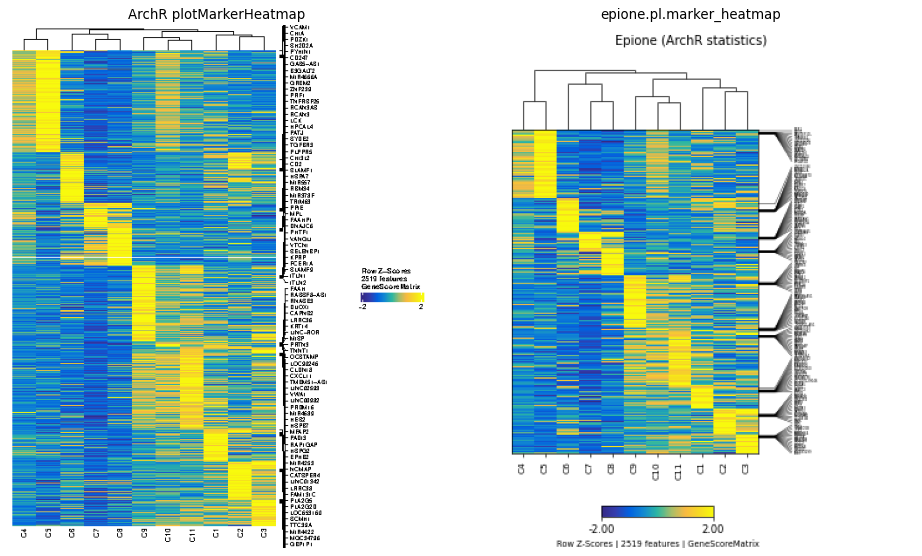

In [13]:
se_gs = pc.load_markers(REF, 'GS')
pdf = REF / 'hm_gs_rows.pdf'
png = WORK / 'hm_gs_rows_archr.png'
if shutil.which('gs') and not png.exists():
    subprocess.run(['gs', '-q', '-dSAFER', '-dBATCH', '-dNOPAUSE', '-sDEVICE=png16m', '-r60',
                    f'-sOutputFile={png}', str(pdf)], check=True)
fig, res_r = epi.pl.marker_heatmap(se_gs, cut_off='FDR <= 0.01 & Log2FC >= 1.25',
                                   figsize=(6, 7), title='Epione (ArchR statistics)', show=False)
fig.savefig(WORK / 'hm_gs_rows_epione.png', dpi=60); plt.close(fig)
f, axs = plt.subplots(1, 2, figsize=(12, 7))
for ax, p, t in zip(axs, [png, WORK / 'hm_gs_rows_epione.png'], ['ArchR plotMarkerHeatmap', 'epione.pl.marker_heatmap']):
    if p.exists():
        ax.imshow(plt.imread(p))
    ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show()

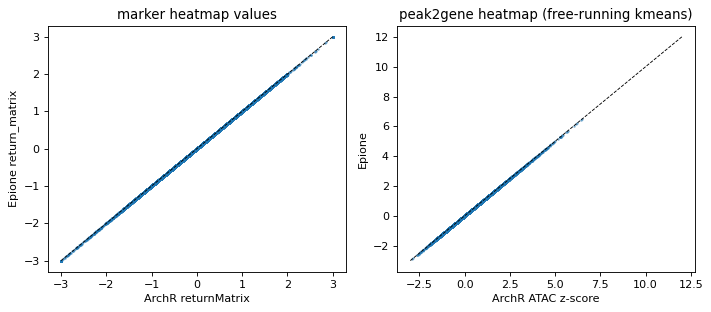

max |Δ| ATAC (free-running): 0.0


In [14]:
# Element-wise agreement across all nine configurations
f, axs = plt.subplots(1, 2, figsize=(9, 4))
xs, ys = [], []
for name, (tag, kw) in pc.CONFIGS.items():
    py = epi.pl.marker_heatmap_matrix(pc.load_markers(REF, tag) if tag == 'PK' else se_gs, **kw).matrix.to_numpy()
    r, _, _ = pc.read_bin(REF, f'hm_{name}__mat')
    sel = np.random.default_rng(0).choice(py.size, min(py.size, 4000), replace=False)
    xs.append(r.ravel()[sel]); ys.append(py.ravel()[sel])
x, y = np.concatenate(xs), np.concatenate(ys)
axs[0].scatter(x, y, s=2, alpha=0.4); axs[0].plot([-3, 3], [-3, 3], 'k--', lw=0.8)
axs[0].set_xlabel('ArchR returnMatrix'); axs[0].set_ylabel('Epione return_matrix'); axs[0].set_title('marker heatmap values')
ra, _, _ = pc.read_bin(REF, 'p2g_default__ATAC')
inp = pc.load_p2g(REF)
res_f = epi.pl.peak2gene_heatmap(**inp, k=25, n_plot=25000, seed=1, return_matrices=True)
sel = np.random.default_rng(0).choice(ra.size, 20000, replace=False)
axs[1].scatter(ra.ravel()[sel], res_f.atac.to_numpy().ravel()[sel], s=2, alpha=0.4)
axs[1].plot([-3, 12], [-3, 12], 'k--', lw=0.8)
axs[1].set_xlabel('ArchR ATAC z-score'); axs[1].set_ylabel('Epione'); axs[1].set_title('peak2gene heatmap (free-running kmeans)')
plt.tight_layout(); plt.show()
print('max |Δ| ATAC (free-running):', np.abs(ra - res_f.atac.to_numpy()).max())

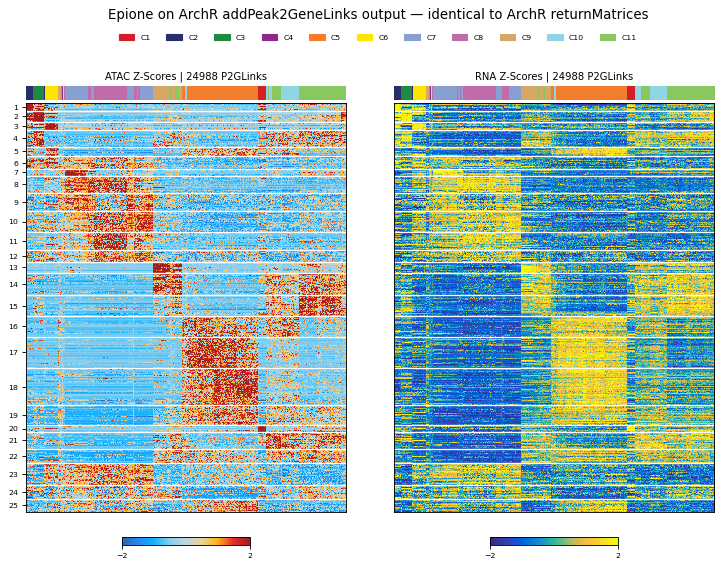

In [15]:
fig = epi.pl._marker_heatmap.plot_peak2gene_heatmap_result(res_f, figsize=(10, 7), all_groups=inp['cell_groups'])
fig.suptitle('Epione on ArchR addPeak2GeneLinks output — identical to ArchR returnMatrices', y=1.02)
plt.show()

### End-to-end with Epione's own upstream steps (informational)

When Epione computes the statistics itself (`find_marker_features`,
`peak_to_gene`) the inputs to the heatmap differ from ArchR's. Those upstream
functions are separate implementations, and their parity is out of scope for
this port, so these numbers are reported but not gated.

In [16]:
e2e = pc.e2e_metrics(WORK)
pd.Series({k: v for k, v in e2e.items() if not isinstance(v, dict)}).to_frame('value')

,value
gs_log2fc_spearman,7.894612e-01
gs_top50_jaccard_median,4.492754e-01
gs_heatmap_marker_jaccard,4.822229e-01
gs_heatmap_n_archr,2.519000e+03
gs_heatmap_n_epione,2.442000e+03
p2g_shared_pairs,1.097714e+06
p2g_pairs_archr,1.097714e+06
p2g_pairs_epione,1.100582e+06
p2g_correlation_spearman,8.887650e-01


## Notes

* `cut_off` takes R syntax: `&`, `|`, `!`, comparisons, `abs()`, `log2()`,
  etc. It uses R's NA logic (`NA & FALSE` is `FALSE`), so rows with NA statistics
  are kept or dropped exactly as in ArchR.
* `subset_markers` uses 1-based row indices, as in R.
* `peak2gene_heatmap(rng_kind="Mersenne-Twister")` matches an R session that never
  called `addArchRThreads(threads > 1)`.
* ArchR quirk reproduced: with `grep_exclude`, the default labels are taken from
  rows *before* exclusion (as in `plotMarkerHeatmap`).